# 🏦 Loan Approval Prediction: End-to-End Pure Machine Learning
**Objective**: Build and evaluate a pure machine learning pipeline to automate loan eligibility prediction. Hyperparameters are systematically tuned using **GridSearchCV**.

### Dataset Overview (Kaggle / Analytics Vidhya)
- **Target Variable**: `Loan_Status` (Y: Approved, N: Rejected)
- **Features**:
  - `Loan_ID`: Unique Loan ID (dropped)
  - `Gender`: Male / Female
  - `Married`: Applicant marital status (Yes / No)
  - `Dependents`: Number of dependents (0, 1, 2, 3+)
  - `Education`: Graduate / Not Graduate
  - `Self_Employed`: Self-employed status (Yes / No)
  - `ApplicantIncome`: Applicant's income
  - `CoapplicantIncome`: Co-applicant's income
  - `LoanAmount`: Loan amount in thousands
  - `Loan_Amount_Term`: Term of loan in months
  - `Credit_History`: Credit history meets guidelines (1.0 = Yes, 0.0 = No)
  - `Property_Area`: Urban / Semiurban / Rural


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)


## 1. Data Inspection


In [2]:
# Load the dataset
df = pd.read_csv('data/train.csv')

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())
df.info()
display(df.describe())


Dataset Dimensions: 614 rows, 13 columns



,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [3]:
# Check missing value distribution
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct.round(2)})
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))


,Missing Count,Percentage (%)
Credit_History,50,8.14
Self_Employed,32,5.21
LoanAmount,22,3.58
Dependents,15,2.44
Loan_Amount_Term,14,2.28
Gender,13,2.12
Married,3,0.49


## 2. Exploratory Data Analysis (EDA)


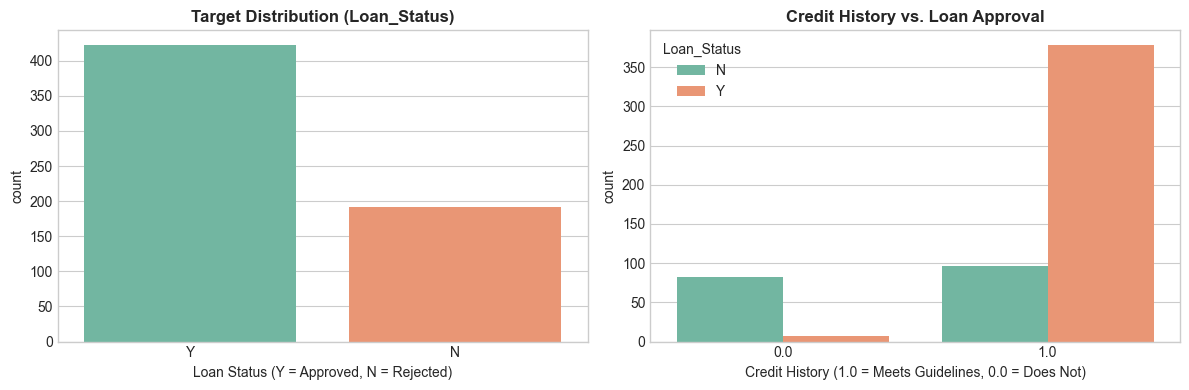

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Target Distribution
sns.countplot(data=df, x='Loan_Status', hue='Loan_Status', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Target Distribution (Loan_Status)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Loan Status (Y = Approved, N = Rejected)')

# 2. Credit History vs Loan Status
sns.countplot(data=df, x='Credit_History', hue='Loan_Status', palette='Set2', ax=axes[1])
axes[1].set_title('Credit History vs. Loan Approval', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Credit History (1.0 = Meets Guidelines, 0.0 = Does Not)')
plt.tight_layout()
plt.show()


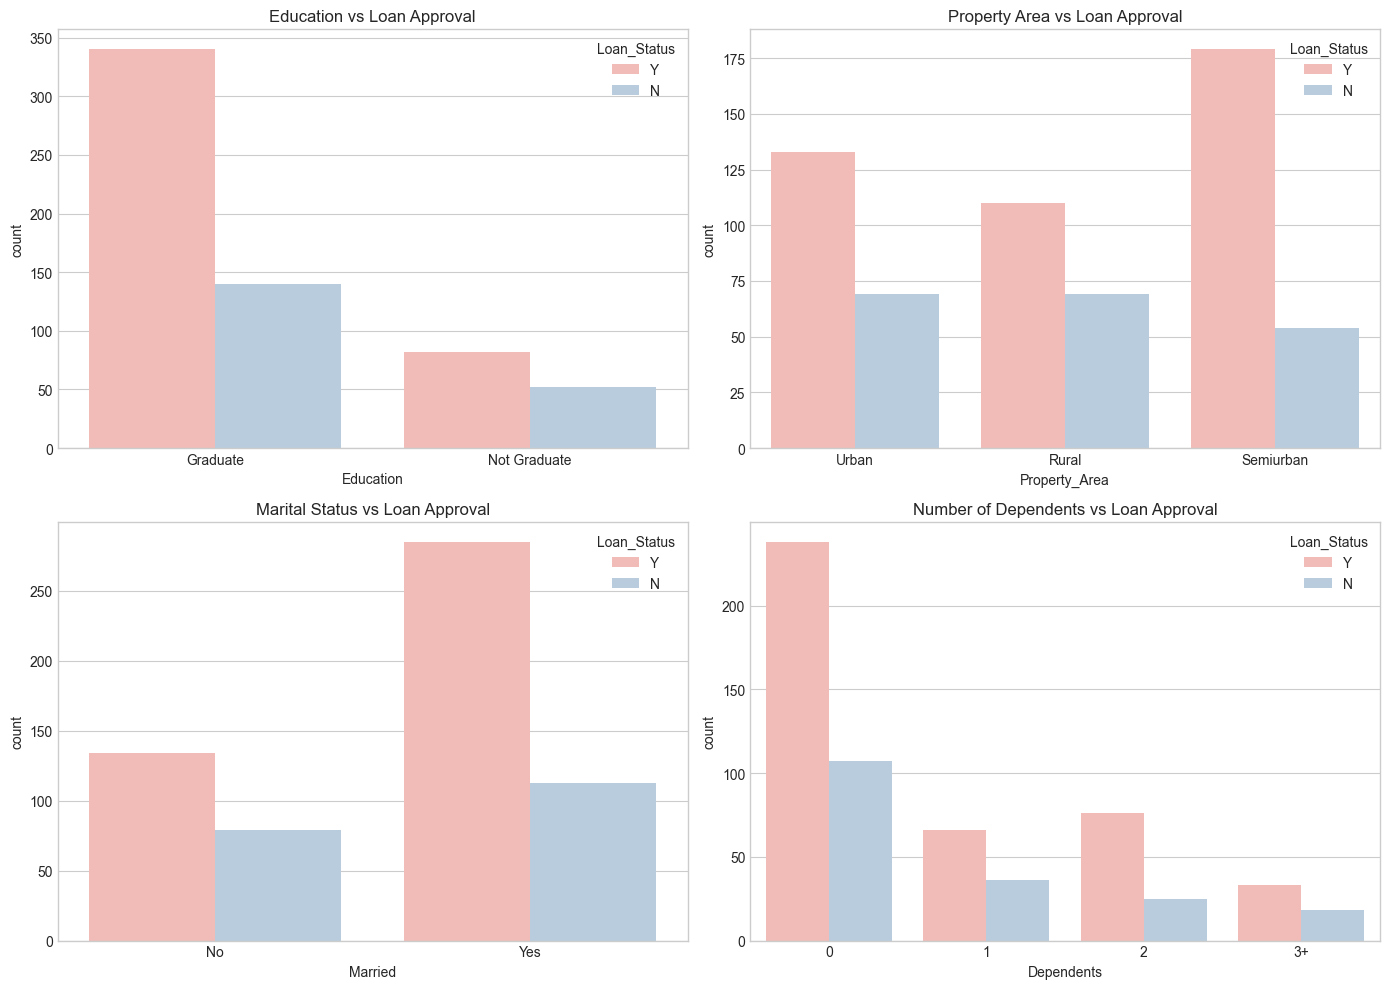

In [5]:
# Demographic & Property Area distributions vs Loan Status
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='Education', hue='Loan_Status', palette='Pastel1', ax=axes[0, 0])
axes[0, 0].set_title('Education vs Loan Approval')

sns.countplot(data=df, x='Property_Area', hue='Loan_Status', palette='Pastel1', ax=axes[0, 1])
axes[0, 1].set_title('Property Area vs Loan Approval')

sns.countplot(data=df, x='Married', hue='Loan_Status', palette='Pastel1', ax=axes[1, 0])
axes[1, 0].set_title('Marital Status vs Loan Approval')

sns.countplot(data=df, x='Dependents', hue='Loan_Status', palette='Pastel1', ax=axes[1, 1])
axes[1, 1].set_title('Number of Dependents vs Loan Approval')

plt.tight_layout()
plt.show()


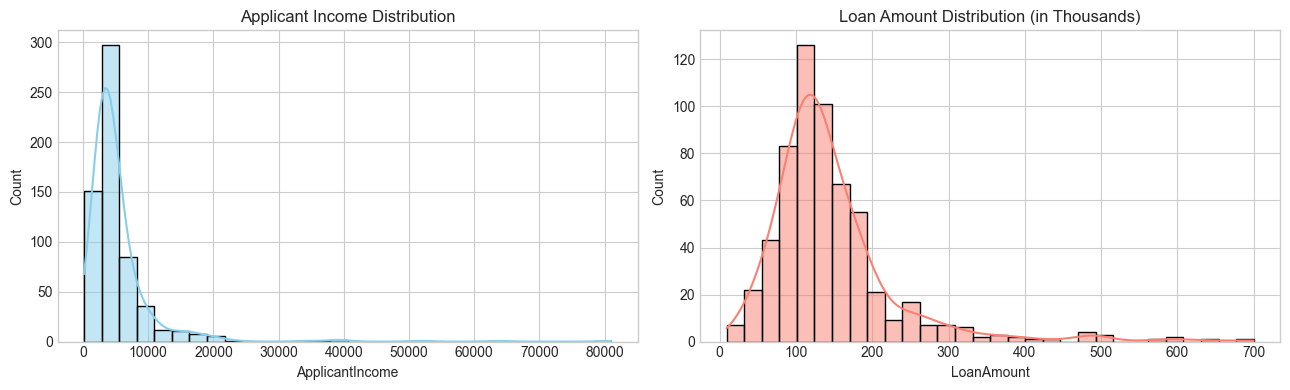

In [6]:
# Numerical feature distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df['ApplicantIncome'], kde=True, bins=30, color='skyblue', ax=axes[0])
axes[0].set_title('Applicant Income Distribution')

sns.histplot(df['LoanAmount'].dropna(), kde=True, bins=30, color='salmon', ax=axes[1])
axes[1].set_title('Loan Amount Distribution (in Thousands)')

plt.tight_layout()
plt.show()


## 3. Data Preprocessing


In [7]:
# Separate features and target
X = df.drop(columns=['Loan_ID', 'Loan_Status'])
y = df['Loan_Status'].map({'Y': 1, 'N': 0})

# Feature grouping
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
cat_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']

# Pipelines for numeric and categorical subsets
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Full preprocessor
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])


## 4. Train/Test Split and Hyperparameter Tuning with GridSearchCV

We perform an 80/20 stratified split. We preprocess the data and then run **GridSearchCV** with **5-fold Stratified Cross-Validation** directly over pure model hyperparameters:
1. **Logistic Regression**: Regularization strength `C`
2. **Gradient Boosting**: `n_estimators`, `learning_rate`, and `max_depth`
3. **Random Forest**: Number of trees (`n_estimators`), tree depth (`max_depth`), and split criteria (`min_samples_split`)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Fit preprocessor on training data and transform splits
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")


Training samples: 491
Testing samples:  123


In [9]:
# Define models and their hyperparameter grids without prefixes
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_configs = {
    'Logistic Regression': {
        'model': LogisticRegression(random_state=42, max_iter=1000),
        'param_grid': {
            'C': [0.01, 0.05, 0.1, 0.5, 1.0, 10.0]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'param_grid': {
            'n_estimators': [50, 100, 150],
            'learning_rate': [0.01, 0.05, 0.1],
            'max_depth': [2, 3, 4]
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'param_grid': {
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 8, None],
            'min_samples_split': [2, 5]
        }
    }
}

grid_search_results = {}
best_pipelines = {}

for name, config in model_configs.items():
    print(f"\n=================== Tuning {name} ===================")
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['param_grid'],
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )
    
    grid.fit(X_train_prep, y_train)
    grid_search_results[name] = grid
    
    # Assemble end-to-end pipeline with the fitted preprocessor and the tuned estimator
    best_pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('model', grid.best_estimator_)
    ])
    
    print(f"Optimal Parameters: {grid.best_params_}")
    print(f"Best 5-Fold CV Accuracy: {grid.best_score_:.4f}")



=================== Tuning Logistic Regression ===================
Optimal Parameters: {'C': 0.1}
Best 5-Fold CV Accuracy: 0.8003

=================== Tuning Gradient Boosting ===================
Optimal Parameters: {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}
Best 5-Fold CV Accuracy: 0.7962

=================== Tuning Random Forest ===================
Optimal Parameters: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 50}
Best 5-Fold CV Accuracy: 0.8003


## 5. Model Evaluation and Comparison 


In [10]:
metrics_summary = []

for name, pipe in best_pipelines.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    best_cv = grid_search_results[name].best_score_
    
    metrics_summary.append({
        'Model': name,
        'Best CV Accuracy': best_cv,
        'Test Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'Best Hyperparameters': str(grid_search_results[name].best_params_)
    })

eval_df = pd.DataFrame(metrics_summary).sort_values(by='ROC-AUC', ascending=False)
display(eval_df[['Model', 'Best CV Accuracy', 'Test Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].round(4))


,Model,Best CV Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8003,0.8618,0.8400,0.9882,0.9081,0.8508
2,Random Forest,0.8003,0.8537,0.8317,0.9882,0.9032,0.8098
1,Gradient Boosting,0.7962,0.8455,0.8235,0.9882,0.8984,0.8067


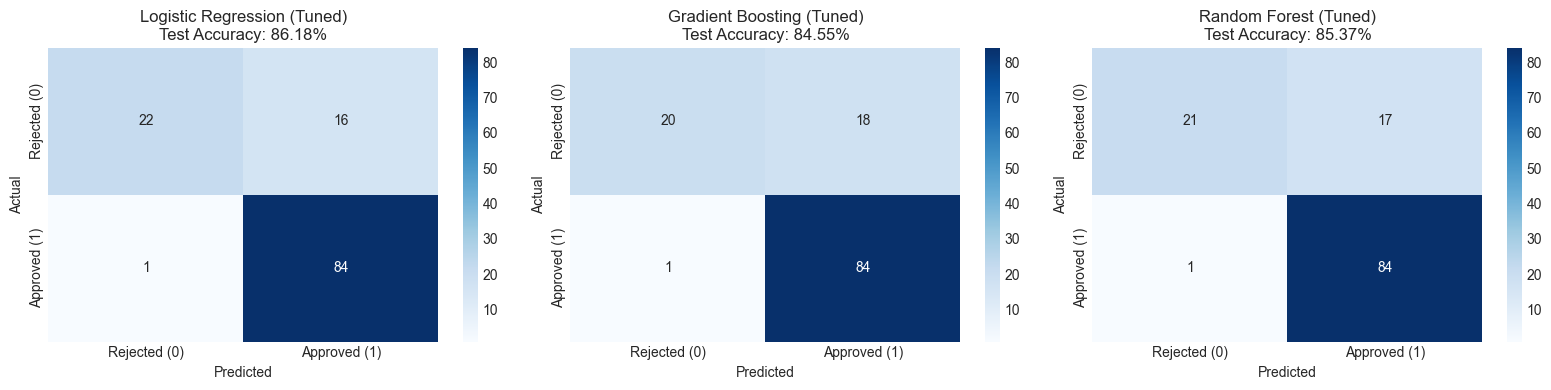

In [11]:
# Plot Confusion Matrices for the Tuned Models
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, (name, pipe) in enumerate(best_pipelines.items()):
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Rejected (0)', 'Approved (1)'],
                yticklabels=['Rejected (0)', 'Approved (1)'])
    axes[idx].set_title(f"{name} (Tuned)\nTest Accuracy: {accuracy_score(y_test, y_pred):.2%}")
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()


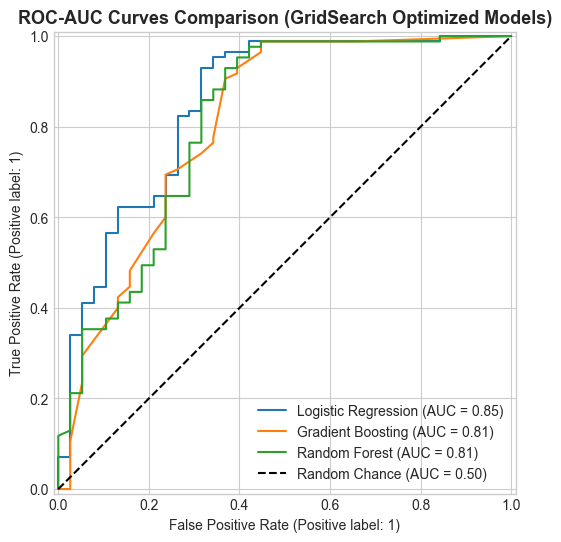

In [12]:
# ROC Curves comparison
plt.figure(figsize=(8, 6))

for name, pipe in best_pipelines.items():
    y_proba = pipe.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, y_proba, name=name, ax=plt.gca())

plt.title('ROC-AUC Curves Comparison (GridSearch Optimized Models)', fontsize=13, fontweight='bold')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.50)')
plt.legend()
plt.show()


## 6. Feature Importance (Logistic Regression Coefficients)


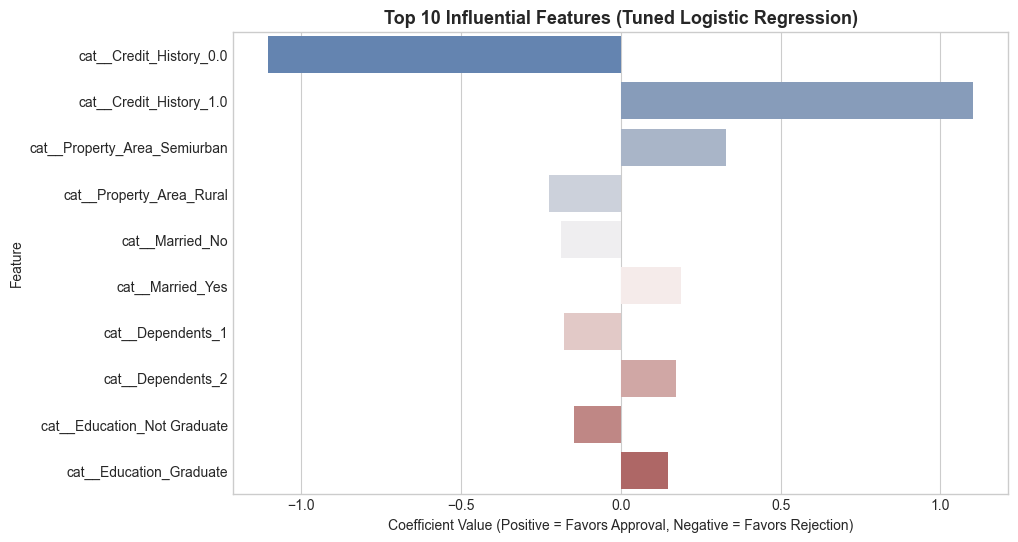

In [13]:
best_pipe = best_pipelines['Logistic Regression']
preprocessor_step = best_pipe.named_steps['preprocessor']
all_feature_names = preprocessor_step.get_feature_names_out()

coefs = best_pipe.named_steps['model'].coef_[0]
feat_importance = pd.DataFrame({'Feature': all_feature_names, 'Coefficient': coefs})
feat_importance['Abs_Coefficient'] = feat_importance['Coefficient'].abs()
feat_importance = feat_importance.sort_values(by='Abs_Coefficient', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_importance.head(10), x='Coefficient', y='Feature', hue='Feature', palette='vlag', legend=False)
plt.title('Top 10 Influential Features (Tuned Logistic Regression)', fontsize=13, fontweight='bold')
plt.xlabel('Coefficient Value (Positive = Favors Approval, Negative = Favors Rejection)')
plt.show()


## 7. Model Serialization for Streamlit Deployment


In [14]:
# Save the best tuned pipeline for Streamlit deployment
joblib.dump(best_pipe, 'loan_pipeline.joblib')
print("Optimal tuned pipeline saved to 'loan_pipeline.joblib'")

# Smoke test with a new synthetic applicant
test_applicant = pd.DataFrame([{
    'Gender': 'Male',
    'Married': 'Yes',
    'Dependents': '2',
    'Education': 'Graduate',
    'Self_Employed': 'No',
    'ApplicantIncome': 5000,
    'CoapplicantIncome': 2000,
    'LoanAmount': 150.0,
    'Loan_Amount_Term': 360.0,
    'Credit_History': 1.0,
    'Property_Area': 'Semiurban'
}])

loaded_pipe = joblib.load('loan_pipeline.joblib')
prediction = loaded_pipe.predict(test_applicant)[0]
probability = loaded_pipe.predict_proba(test_applicant)[0][1]

status = 'APPROVED' if prediction == 1 else 'REJECTED'
print(f"Test Applicant Status: {status} (Approval Probability: {probability:.1%})")


Optimal tuned pipeline saved to 'loan_pipeline.joblib'
Test Applicant Status: APPROVED (Approval Probability: 86.0%)
